In [2]:
import json
import re
import pandas as pd
import numpy as np
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns
from collections import defaultdict, Counter

print("✅ All libraries imported successfully!")

✅ All libraries imported successfully!


In [3]:
# Cell 2: Load Results
import os

base_path = "/home/jovyan/Works/MSc_Thesis/mh_function_calling/model_evaluation/comprehensive_evaluation"
# Load results
results_file = f"{base_path}/fc_predictions_and_ground_truth.csv"
results_json_file = f"{base_path}/fc_detailed_results.json"

print("📊 Loading evaluation data...")

# Load CSV data
df = pd.read_csv(results_file)

# Load detailed JSON data (for complex parameters)
with open(results_json_file, 'r') as f:
    detailed_results = json.load(f)

print(f"✅ Loaded data with shape: {df.shape}")
print(f"📋 Columns: {list(df.columns)}")
print(f"🎯 Ready to evaluate {len(detailed_results)} predictions")

# Check type distribution (using existing type field)
print(f"\n📈 Type Distribution:")
print(df['type'].value_counts())

📊 Loading evaluation data...
✅ Loaded data with shape: (765, 14)
📋 Columns: ['sample_id', 'patient_id', 'query', 'type', 'ground_truth_response', 'predicted_response', 'ground_truth_function_name', 'predicted_function_name', 'ground_truth_parameters', 'predicted_parameters', 'function_extracted', 'function_name_correct', 'parameters_correct', 'extraction_method']
🎯 Ready to evaluate 765 predictions

📈 Type Distribution:
type
explicit        192
behavioral      159
metaphorical    143
symptom         143
implicit        128
Name: count, dtype: int64


In [4]:
# Cell 3: Calculate Overall Metrics
def calculate_metrics(results):
    """Calculate comprehensive metrics for function calling evaluation"""
    
    # Overall metrics
    total_samples = len(results)
    extraction_success = sum(r['function_extracted'] for r in results) / total_samples
    overall_success = sum(r['function_name_correct'] and r['parameters_correct'] for r in results) / total_samples
    
    # Function name metrics
    y_true_functions = [r['ground_truth_function_name'] for r in results]
    y_pred_functions = [r['predicted_function_name'] for r in results]
    
    function_accuracy = accuracy_score(y_true_functions, y_pred_functions)
    
    # Get unique function names
    unique_functions = list(set(y_true_functions + y_pred_functions))
    
    function_precision = precision_score(y_true_functions, y_pred_functions, 
                                       labels=unique_functions, average='weighted', zero_division=0)
    function_recall = recall_score(y_true_functions, y_pred_functions, 
                                 labels=unique_functions, average='weighted', zero_division=0)
    function_f1 = f1_score(y_true_functions, y_pred_functions, 
                          labels=unique_functions, average='weighted', zero_division=0)
    
    # Parameter metrics
    parameter_accuracy = sum(r['parameters_correct'] for r in results) / total_samples
    
    return {
        'total_samples': total_samples,
        'extraction_success': extraction_success,
        'overall_success': overall_success,
        'function_accuracy': function_accuracy,
        'function_precision': function_precision,
        'function_recall': function_recall,
        'function_f1': function_f1,
        'parameter_accuracy': parameter_accuracy,
        'y_true_functions': y_true_functions,
        'y_pred_functions': y_pred_functions,
        'unique_functions': unique_functions
    }

# Calculate overall metrics
overall_metrics = calculate_metrics(detailed_results)
print("📊 Overall metrics calculated!")

📊 Overall metrics calculated!


In [5]:
# Cell 4: Calculate Type-Based Metrics (using existing type field)
def calculate_type_based_metrics(results):
    """Calculate metrics grouped by type (from dataset)"""
    type_metrics = {}
    
    # Group results by type
    results_by_type = defaultdict(list)
    for result in results:
        result_type = result['type']  # Use existing type from dataset
        results_by_type[result_type].append(result)
    
    # Calculate metrics for each type
    for result_type, type_results in results_by_type.items():
        if len(type_results) > 0:
            type_metrics[result_type] = calculate_metrics(type_results)
    
    return type_metrics

# Calculate type-based metrics
type_based_metrics = calculate_type_based_metrics(detailed_results)
print("🎯 Type-based metrics calculated!")
print(f"📈 Types analyzed: {list(type_based_metrics.keys())}")

🎯 Type-based metrics calculated!
📈 Types analyzed: ['behavioral', 'metaphorical', 'explicit', 'implicit', 'symptom']


In [6]:
# Cell 5: Display Comprehensive Results
print("="*80)
print("🎯 COMPREHENSIVE FUNCTION CALLING EVALUATION REPORT")
print("="*80)

print(f"\n📊 OVERALL PERFORMANCE:")
print(f"   Total Samples Evaluated: {overall_metrics['total_samples']}")
print(f"   Function Extraction Success: {overall_metrics['extraction_success']:.3f}")
print(f"   Complete Success Rate (Name + Params): {overall_metrics['overall_success']:.3f}")

print(f"\n🎯 OVERALL FUNCTION NAME METRICS:")
print(f"   Accuracy:  {overall_metrics['function_accuracy']:.3f}")
print(f"   Precision: {overall_metrics['function_precision']:.3f}")
print(f"   Recall:    {overall_metrics['function_recall']:.3f}")
print(f"   F1-Score:  {overall_metrics['function_f1']:.3f}")

print(f"\n⚙️ OVERALL PARAMETER METRICS:")
print(f"   Parameter Accuracy: {overall_metrics['parameter_accuracy']:.3f}")

# Function-wise breakdown
function_breakdown = defaultdict(lambda: {'correct': 0, 'total': 0})
for result in detailed_results:
    func_name = result['ground_truth_function_name']
    function_breakdown[func_name]['total'] += 1
    if result['function_name_correct']:
        function_breakdown[func_name]['correct'] += 1

print(f"\n📈 FUNCTION-WISE BREAKDOWN:")
for func_name, stats in function_breakdown.items():
    accuracy = stats['correct'] / stats['total'] if stats['total'] > 0 else 0
    print(f"   {func_name}: {accuracy:.3f} ({stats['correct']}/{stats['total']})")

print("="*80)

🎯 COMPREHENSIVE FUNCTION CALLING EVALUATION REPORT

📊 OVERALL PERFORMANCE:
   Total Samples Evaluated: 765
   Function Extraction Success: 1.000
   Complete Success Rate (Name + Params): 0.613

🎯 OVERALL FUNCTION NAME METRICS:
   Accuracy:  0.807
   Precision: 0.824
   Recall:    0.807
   F1-Score:  0.811

⚙️ OVERALL PARAMETER METRICS:
   Parameter Accuracy: 0.754

📈 FUNCTION-WISE BREAKDOWN:
   get_sleep_data: 1.000 (38/38)
   get_vo2max_data: 0.698 (30/43)
   get_blood_glucose_data: 0.939 (31/33)
   get_distance_data: 0.767 (33/43)
   get_speed_data: 0.656 (21/32)
   get_stress_data: 0.738 (31/42)
   get_calories_burned_data: 0.674 (29/43)
   get_body_fat_data: 0.767 (33/43)
   get_heart_rate_data: 0.878 (36/41)
   get_steps_data: 0.756 (34/45)
   get_bmr_data: 0.811 (30/37)
   get_body_temp_data: 0.907 (39/43)
   get_blood_pressure_data: 0.912 (31/34)
   get_nutrition_data: 0.952 (40/42)
   get_exercise_session_data: 0.361 (13/36)
   get_height_data: 0.912 (31/34)
   get_oxygen_satur

In [7]:
# Cell 6: Type-Based Performance Analysis with Detailed Metrics
print("\n🎭 TYPE-BASED PERFORMANCE ANALYSIS (DETAILED METRICS)")
print("="*80)

# Create comprehensive type-based metrics table
type_metrics_table = []

for result_type, metrics in type_based_metrics.items():
    type_metrics_table.append({
        'Type': result_type,
        'Samples': metrics['total_samples'],
        'Extraction_Success': metrics['extraction_success'],
        'Overall_Success': metrics['overall_success'],
        'Function_Accuracy': metrics['function_accuracy'],
        'Function_Precision': metrics['function_precision'],
        'Function_Recall': metrics['function_recall'],
        'Function_F1': metrics['function_f1'],
        'Parameter_Accuracy': metrics['parameter_accuracy']
    })

type_metrics_df = pd.DataFrame(type_metrics_table)
print("📊 COMPREHENSIVE TYPE-BASED METRICS TABLE:")
print(type_metrics_df.round(3))

# Display detailed breakdown by type
for result_type, metrics in type_based_metrics.items():
    print(f"\n📋 {result_type.upper()} TYPE DETAILED ANALYSIS:")
    print(f"   Samples: {metrics['total_samples']}")
    print(f"   Extraction Success: {metrics['extraction_success']:.3f}")
    print(f"   Complete Success: {metrics['overall_success']:.3f}")
    print(f"   Function Accuracy: {metrics['function_accuracy']:.3f}")
    print(f"   Function Precision: {metrics['function_precision']:.3f}")
    print(f"   Function Recall: {metrics['function_recall']:.3f}")
    print(f"   Function F1-Score: {metrics['function_f1']:.3f}")
    print(f"   Parameter Accuracy: {metrics['parameter_accuracy']:.3f}")

print("="*80)


🎭 TYPE-BASED PERFORMANCE ANALYSIS (DETAILED METRICS)
📊 COMPREHENSIVE TYPE-BASED METRICS TABLE:
           Type  Samples  Extraction_Success  Overall_Success  \
0    behavioral      159                 1.0            0.579   
1  metaphorical      143                 1.0            0.566   
2      explicit      192                 1.0            0.661   
3      implicit      128                 1.0            0.586   
4       symptom      143                 1.0            0.657   

   Function_Accuracy  Function_Precision  Function_Recall  Function_F1  \
0              0.774               0.816            0.774        0.779   
1              0.692               0.730            0.692        0.701   
2              0.948               0.954            0.948        0.949   
3              0.773               0.822            0.773        0.786   
4              0.797               0.847            0.797        0.799   

   Parameter_Accuracy  
0               0.748  
1               0.80

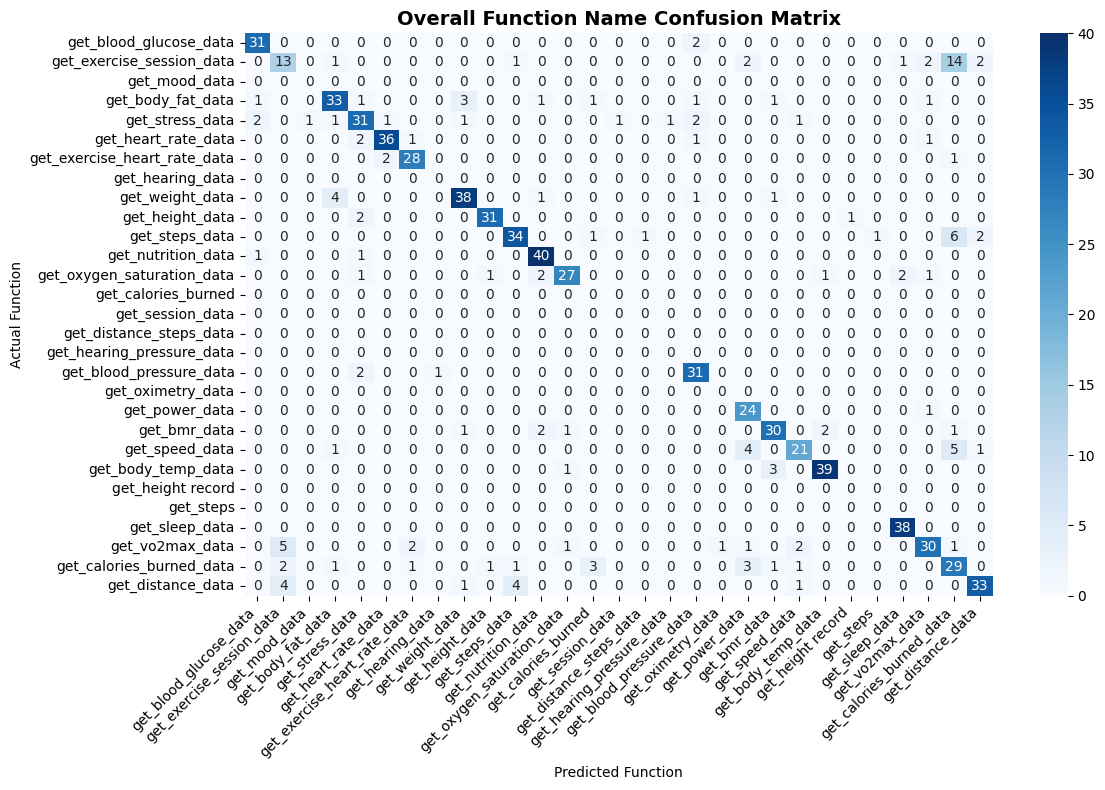


📊 DETAILED CLASSIFICATION REPORT:
                              precision    recall  f1-score   support

      get_blood_glucose_data       0.89      0.94      0.91        33
   get_exercise_session_data       0.54      0.36      0.43        36
               get_mood_data       0.00      0.00      0.00         0
           get_body_fat_data       0.80      0.77      0.79        43
             get_stress_data       0.78      0.74      0.76        42
         get_heart_rate_data       0.92      0.88      0.90        41
get_exercise_heart_rate_data       0.88      0.90      0.89        31
            get_hearing_data       0.00      0.00      0.00         0
             get_weight_data       0.86      0.84      0.85        45
             get_height_data       0.94      0.91      0.93        34
              get_steps_data       0.85      0.76      0.80        45
          get_nutrition_data       0.87      0.95      0.91        42
  get_oxygen_saturation_data       0.90      0.77     

In [8]:
# Cell 7: Confusion Matrix Analysis
# Overall confusion matrix
plt.figure(figsize=(12, 8))
cm_functions = confusion_matrix(overall_metrics['y_true_functions'], 
                               overall_metrics['y_pred_functions'], 
                               labels=overall_metrics['unique_functions'])

sns.heatmap(cm_functions, annot=True, fmt='d', cmap='Blues',
            xticklabels=overall_metrics['unique_functions'], 
            yticklabels=overall_metrics['unique_functions'])
plt.title('Overall Function Name Confusion Matrix', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Function')
plt.ylabel('Actual Function')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Classification Report
print("\n📊 DETAILED CLASSIFICATION REPORT:")
print("="*60)
print(classification_report(overall_metrics['y_true_functions'], 
                          overall_metrics['y_pred_functions'], 
                          labels=overall_metrics['unique_functions'], 
                          zero_division=0))

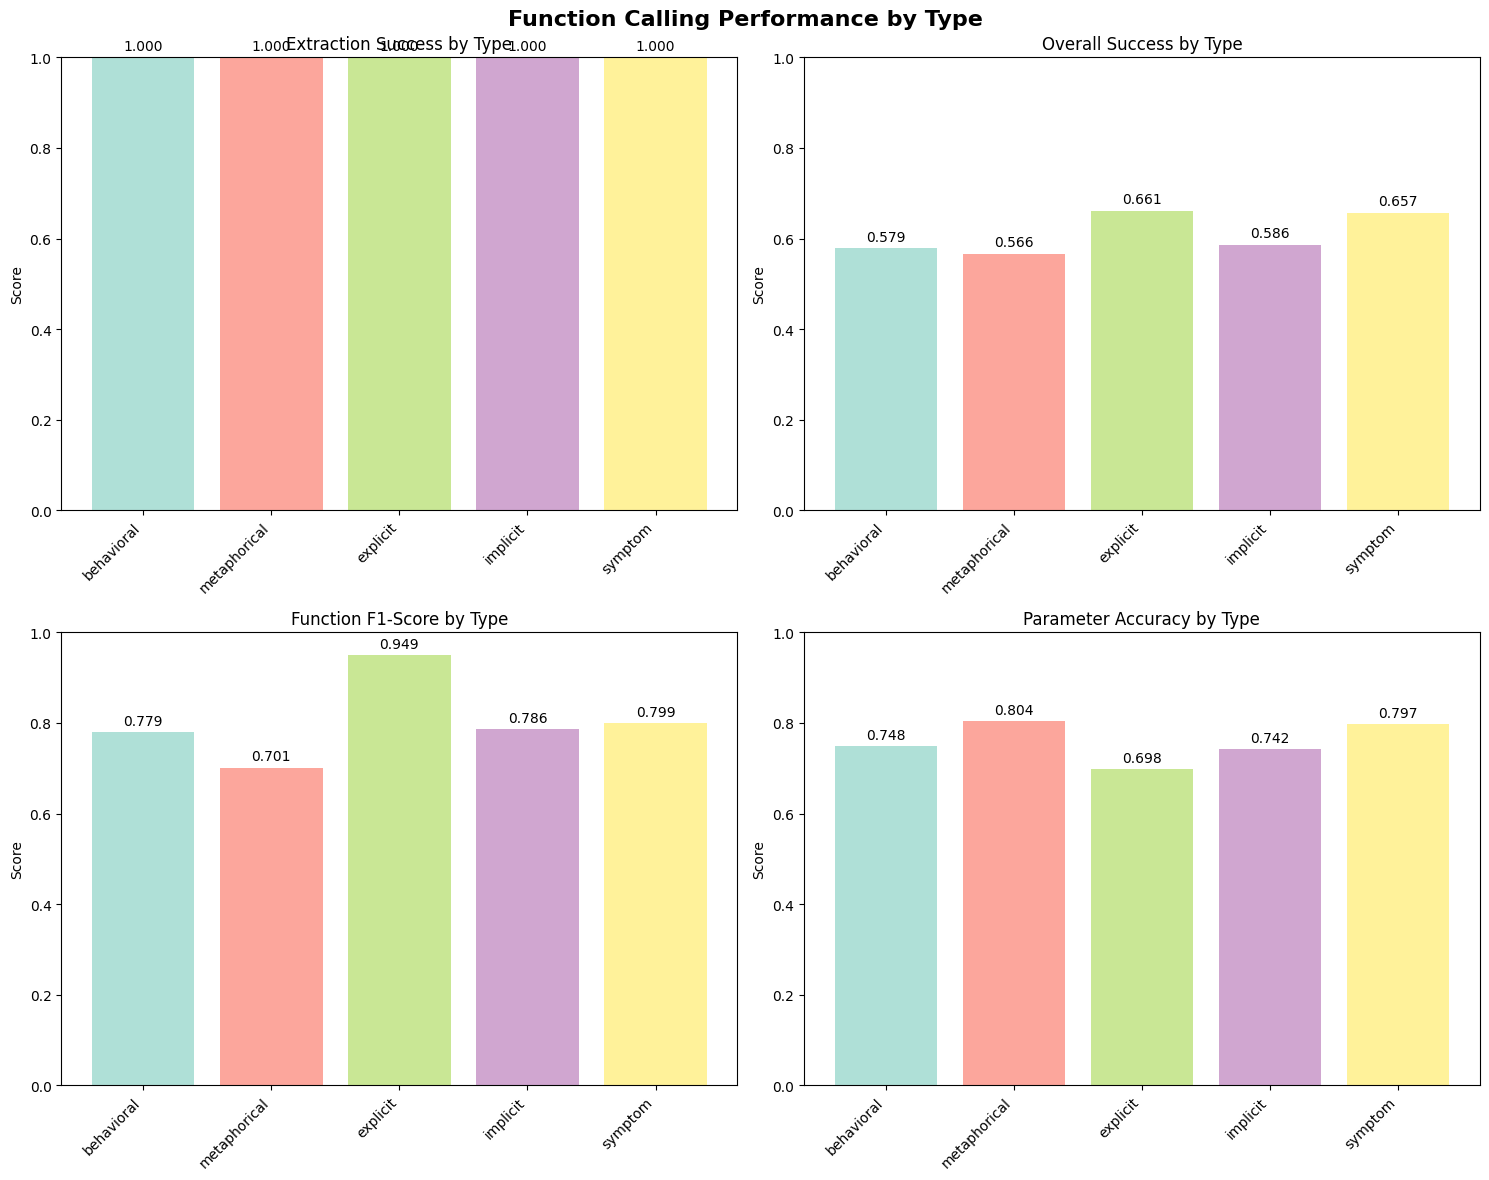

📊 Type-based performance visualization complete!


In [9]:
# Create performance comparison by type
fig, axes = plt.subplots(2, 2, figsize=(15, 12))
fig.suptitle('Function Calling Performance by Type', fontsize=16, fontweight='bold')

# Metrics to plot
metrics_to_plot = ['extraction_success', 'overall_success', 'function_f1', 'parameter_accuracy']
metric_names = ['Extraction Success', 'Overall Success', 'Function F1-Score', 'Parameter Accuracy']

for idx, (metric, name) in enumerate(zip(metrics_to_plot, metric_names)):
    ax = axes[idx // 2, idx % 2]
    
    types = list(type_based_metrics.keys())
    values = [type_based_metrics[t][metric] for t in types]
    
    bars = ax.bar(types, values, alpha=0.7, color=plt.cm.Set3(np.linspace(0, 1, len(types))))
    ax.set_title(f'{name} by Type')
    ax.set_ylabel('Score')
    ax.set_ylim(0, 1)
    
    # Add value labels on bars
    for bar, value in zip(bars, values):
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height + 0.01,
                f'{value:.3f}', ha='center', va='bottom')
    
    plt.setp(ax.get_xticklabels(), rotation=45, ha='right')

plt.tight_layout()
plt.show()

print("📊 Type-based performance visualization complete!")

In [10]:
# Cell 9: Save Comprehensive Results
import os

output_dir = "/home/jovyan/Works/MSc_Thesis/mh_function_calling/model_evaluation/comprehensive_evaluation"

# Save overall metrics
overall_metrics_clean = {k: v for k, v in overall_metrics.items() 
                        if k not in ['y_true_functions', 'y_pred_functions', 'unique_functions']}
overall_metrics_df = pd.DataFrame([overall_metrics_clean])
overall_file = f"{output_dir}/overall_metrics.csv"
overall_metrics_df.to_csv(overall_file, index=False)

# Save type-based metrics
type_metrics_file = f"{output_dir}/type_based_metrics.csv"
type_metrics_df.to_csv(type_metrics_file, index=False)

# Save classification report
classification_dict = classification_report(overall_metrics['y_true_functions'], 
                                          overall_metrics['y_pred_functions'], 
                                          labels=overall_metrics['unique_functions'], 
                                          zero_division=0, 
                                          output_dict=True)
classification_df = pd.DataFrame(classification_dict).transpose()
classification_file = f"{output_dir}/classification_report.csv"
classification_df.to_csv(classification_file, index=True)

print(f"✅ Saved overall metrics to: {overall_file}")
print(f"✅ Saved type-based metrics to: {type_metrics_file}")
print(f"✅ Saved classification report to: {classification_file}")
print("🎉 Function calling evaluation complete!")

# Summary of key findings
print(f"\n📋 EVALUATION SUMMARY:")
print(f"   Overall Accuracy: {overall_metrics['function_accuracy']:.3f}")
print(f"   Overall F1-Score: {overall_metrics['function_f1']:.3f}")
print(f"   Best Performing Type: {max(type_based_metrics.items(), key=lambda x: x[1]['function_f1'])[0]}")
print(f"   Worst Performing Type: {min(type_based_metrics.items(), key=lambda x: x[1]['function_f1'])[0]}")

✅ Saved overall metrics to: /home/jovyan/Works/MSc_Thesis/mh_function_calling/model_evaluation/comprehensive_evaluation/overall_metrics.csv
✅ Saved type-based metrics to: /home/jovyan/Works/MSc_Thesis/mh_function_calling/model_evaluation/comprehensive_evaluation/type_based_metrics.csv
✅ Saved classification report to: /home/jovyan/Works/MSc_Thesis/mh_function_calling/model_evaluation/comprehensive_evaluation/classification_report.csv
🎉 Function calling evaluation complete!

📋 EVALUATION SUMMARY:
   Overall Accuracy: 0.807
   Overall F1-Score: 0.811
   Best Performing Type: explicit
   Worst Performing Type: metaphorical
